# Model comparison: selection points

Compares every base model in `src/model_dispatcher.py` at the four model selection points run by
`src/folds.sh`: gameweeks **21, 26, 31, 36** (`config.VALID_FOLDS`), for each position **GK, DEF, MID, FWD**.
At each point the models train on all earlier gameweeks and are validated on that gameweek.

Sections 1 to 7 only use these validation scores. The selected model is then used for the next 5 gameweeks;
section 8 prints how every model and the selection procedure score on those gameweeks with `src/compare.py`.


In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.insert(0, "../src")
import compare
import config

MODELS_DIR = Path("../models")
POSITIONS = config.POSITIONS
BASELINE = "dummy"

# Plot styling: recessive grid, one accent colour, grey for everything else.
ACCENT, ACCENT_2, MUTED = "#2a78d6", "#eb6834", "#b4b2a9"
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.edgecolor": "#8a8980",
        "axes.titleweight": "bold",
    }
)
pd.set_option("display.precision", 4)

## 1. Load and tag the results

In [2]:
# One results file per position, written by train.py. Keep the latest run of each model x fold.
raw = pd.concat(
    [pd.read_csv(MODELS_DIR / f"{p}_results.csv").assign(pos=p) for p in POSITIONS],
    ignore_index=True,
)
res = raw.drop_duplicates(["model", "fold", "pos"], keep="last")
res = res[res.fold.isin(config.VALID_FOLDS)].copy()
print(
    f"{len(raw)} result rows, {len(res)} after keeping the latest run on the validation folds"
)


144 result rows, 144 after keeping the latest run on the validation folds


In [3]:
# Sanity check: one row per model x fold x position.
counts = res.groupby(["model", "pos"]).size().unstack()
assert (counts == len(config.VALID_FOLDS)).all().all(), counts

# Model order: by overall mean MAE (best first). Used for every table and chart below.
MODEL_ORDER = res.groupby("model")["mae"].mean().sort_values().index.tolist()
res["pos"] = pd.Categorical(res["pos"], POSITIONS, ordered=True)
N_CELLS = res.groupby(["fold", "pos"], observed=True).ngroups
print(
    f"{len(res)} rows | models: {MODEL_ORDER} | folds: {sorted(res.fold.unique())} | {N_CELLS} cells"
)


144 rows | models: ['cat', 'svr', 'lgbm', 'xgb', 'rf', 'hgb', 'ridge', 'dt', 'dummy'] | folds: [21, 26, 31, 36] | 16 cells


## 2. Leaderboard

Mean and standard deviation of MAE and R² across all 16 fold × position cells (4 folds × 4 positions), plus the MAE improvement
over the `dummy` (mean) baseline and the average rank of each model within a cell (1 = best).

In [4]:
res["mae_rank"] = res.groupby(["fold", "pos"], observed=True)["mae"].rank()
base = res[res.model == BASELINE].set_index(["fold", "pos"])["mae"]
res["mae_vs_dummy"] = 1 - res["mae"] / res.set_index(["fold", "pos"]).index.map(base)

leader = (
    res.groupby("model")
    .agg(
        mae_mean=("mae", "mean"),
        mae_std=("mae", "std"),
        r2_mean=("r2", "mean"),
        r2_std=("r2", "std"),
        mae_gain_vs_dummy=("mae_vs_dummy", "mean"),
        avg_rank=("mae_rank", "mean"),
        wins=("mae_rank", lambda r: int((r == 1).sum())),
    )
    .loc[MODEL_ORDER]
)
(
    leader.style.format(
        {"mae_gain_vs_dummy": "{:.1%}", "avg_rank": "{:.2f}", "wins": "{:d}"},
        precision=4,
    )
    .background_gradient(subset=["mae_mean", "avg_rank"], cmap="Blues_r")
    .background_gradient(subset=["r2_mean"], cmap="Blues")
)

,mae_mean,mae_std,r2_mean,r2_std,mae_gain_vs_dummy,avg_rank,wins
model,,,,,,,
cat,0.7774,0.2273,0.6432,0.1725,47.0%,2.88,6
svr,0.7783,0.2035,0.6398,0.1781,46.8%,3.50,3
lgbm,0.7866,0.2143,0.6357,0.1738,46.4%,3.25,2
xgb,0.7979,0.2273,0.6264,0.1988,45.6%,4.00,0
rf,0.8027,0.2145,0.6443,0.1663,45.2%,4.06,2
hgb,0.8128,0.2098,0.6207,0.1659,45.0%,4.56,2
ridge,0.8856,0.2008,0.5709,0.2010,39.3%,7.00,0
dt,0.9074,0.2140,0.5576,0.1973,38.4%,6.81,1
dummy,1.4970,0.2885,-0.0122,0.0128,0.0%,8.94,0


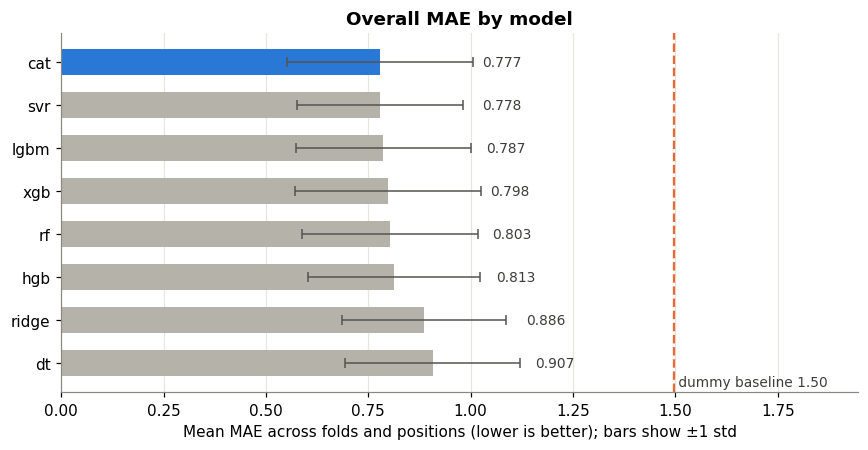

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
lb = leader.drop(BASELINE)
colors = [ACCENT if m == lb.index[0] else MUTED for m in lb.index]
ax.barh(
    lb.index,
    lb["mae_mean"],
    xerr=lb["mae_std"],
    color=colors,
    height=0.6,
    error_kw=dict(ecolor="#55544f", lw=1, capsize=3),
)
for y, (m, v) in enumerate(lb["mae_mean"].items()):
    ax.text(
        v + lb["mae_std"].max() * 1.1,
        y,
        f"{v:.3f}",
        va="center",
        fontsize=9,
        color="#3d3d3a",
    )
ax.axvline(leader.loc[BASELINE, "mae_mean"], color=ACCENT_2, ls="--", lw=1.5)
ax.text(
    leader.loc[BASELINE, "mae_mean"],
    len(lb) - 0.4,
    f" dummy baseline {leader.loc[BASELINE, 'mae_mean']:.2f}",
    color="#3d3d3a",
    fontsize=9,
    va="bottom",
)
ax.set_xlim(0, leader.loc[BASELINE, "mae_mean"] * 1.3)
ax.invert_yaxis()
ax.set_xlabel("Mean MAE across folds and positions (lower is better); bars show ±1 std")
ax.set_title("Overall MAE by model")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 3. Performance by position

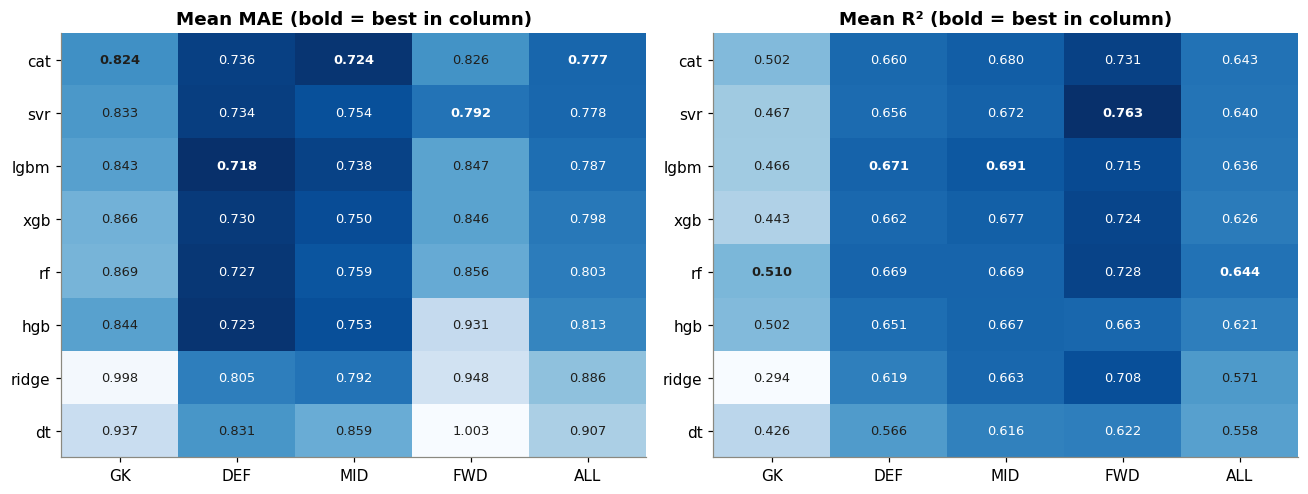

pos,GK,DEF,MID,FWD,ALL
model,,,,,
cat,0.8235,0.7361,0.7238,0.8263,0.7774
svr,0.8330,0.7344,0.7536,0.7923,0.7783
lgbm,0.8432,0.7182,0.7383,0.8466,0.7866
xgb,0.8655,0.7303,0.7498,0.8462,0.7979
rf,0.8691,0.7266,0.7591,0.8562,0.8027
hgb,0.8443,0.7229,0.7526,0.9313,0.8128
ridge,0.9981,0.8047,0.7916,0.9478,0.8856
dt,0.9372,0.8307,0.8586,1.0031,0.9074
dummy,1.2412,1.3553,1.4815,1.9102,1.4970


In [6]:
mae_pos = res.pivot_table(
    index="model", columns="pos", values="mae", aggfunc="mean", observed=True
).loc[MODEL_ORDER]
r2_pos = res.pivot_table(
    index="model", columns="pos", values="r2", aggfunc="mean", observed=True
).loc[MODEL_ORDER]
mae_pos["ALL"] = leader["mae_mean"]
r2_pos["ALL"] = leader["r2_mean"]


def heatmap(ax, df, title, cmap, fmt="{:.3f}", higher_better=False):
    data = df.values
    im = ax.imshow(data, cmap=cmap, aspect="auto")
    ax.set_xticks(range(df.shape[1]), df.columns)
    ax.set_yticks(range(df.shape[0]), df.index)
    ax.grid(False)
    best = df.idxmax() if higher_better else df.idxmin()
    for i, m in enumerate(df.index):
        for j, c in enumerate(df.columns):
            v = data[i, j]
            r, g, b, _ = im.cmap(im.norm(v))
            dark = (0.2126 * r + 0.7152 * g + 0.0722 * b) < 0.5  # cell luminance
            ax.text(
                j,
                i,
                fmt.format(v),
                ha="center",
                va="center",
                fontsize=8.5,
                color="white" if dark else "#1f1f1d",
                fontweight="bold" if best[c] == m else "normal",
            )
    ax.set_title(title)


no_dummy = [m for m in MODEL_ORDER if m != BASELINE]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
heatmap(axes[0], mae_pos.loc[no_dummy], "Mean MAE (bold = best in column)", "Blues_r")
heatmap(
    axes[1],
    r2_pos.loc[no_dummy],
    "Mean R² (bold = best in column)",
    "Blues",
    higher_better=True,
)
plt.tight_layout()
plt.show()
display(mae_pos)

## 4. Stability across folds

Validation sets are a single gameweek per position, so per-fold scores are noisy.
The left chart shows how each model's MAE moves across folds, averaged over positions; the three best models are coloured.
The box plot shows the spread of all 16 cells per model.

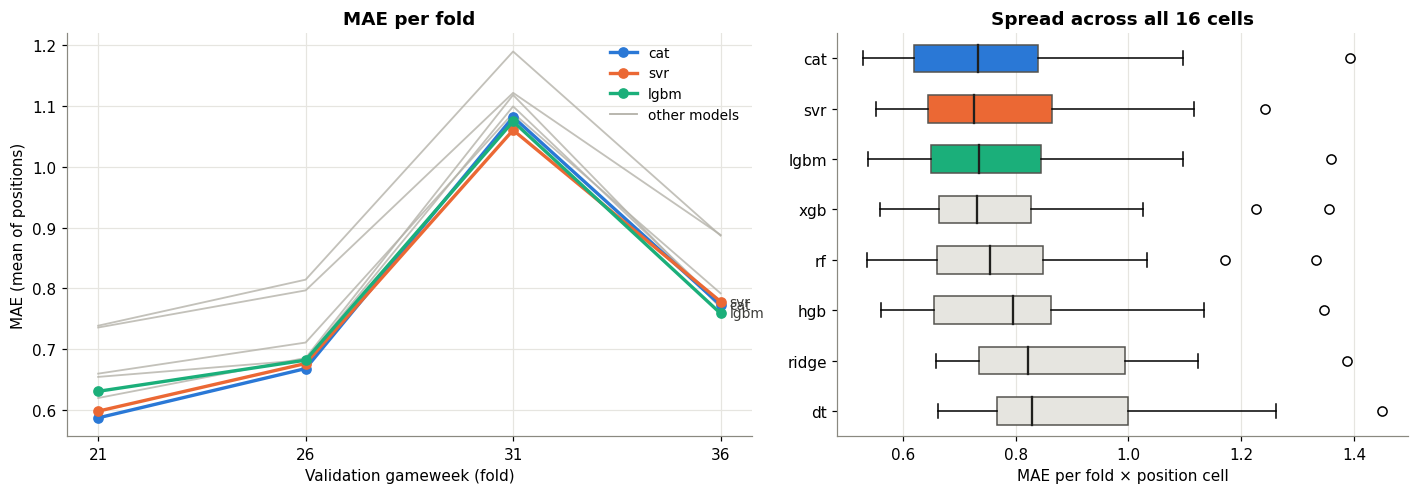

In [7]:
top3 = [m for m in MODEL_ORDER if m != BASELINE][:3]
top_colors = dict(zip(top3, [ACCENT, ACCENT_2, "#1baf7a"]))

by_fold = res.pivot_table(
    index="fold", columns="model", values="mae", aggfunc="mean", observed=True
)
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1.2, 1])
)

ax = axes[0]
for m in no_dummy:
    if m in top3:
        continue
    ax.plot(by_fold.index, by_fold[m], color=MUTED, lw=1.2, alpha=0.8)
for m in top3:
    ax.plot(
        by_fold.index,
        by_fold[m],
        color=top_colors[m],
        lw=2.2,
        marker="o",
        ms=6,
        label=m,
    )
    ax.annotate(
        m,
        (by_fold.index[-1], by_fold[m].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color="#3d3d3a",
    )
ax.plot([], [], color=MUTED, lw=1.2, label="other models")
ax.set_xticks(by_fold.index)
ax.set_xlabel("Validation gameweek (fold)")
ax.set_ylabel("MAE (mean of positions)")
ax.set_title("MAE per fold")
ax.legend(frameon=False, fontsize=9)

ax = axes[1]
data = [res.loc[res.model == m, "mae"].values for m in no_dummy]
bp = ax.boxplot(
    data,
    vert=False,
    labels=no_dummy,
    patch_artist=True,
    widths=0.55,
    medianprops=dict(color="#1f1f1d", lw=1.5),
)
for patch, m in zip(bp["boxes"], no_dummy):
    patch.set_facecolor(top_colors.get(m, "#e6e5e0"))
    patch.set_edgecolor("#55544f")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE per fold × position cell")
ax.set_title(f"Spread across all {N_CELLS} cells")
plt.tight_layout()
plt.show()

In [8]:
# MAE per fold for each position: a table is easier to read than nine overlapping lines.
(
    res[res.model.isin(no_dummy)]
    .pivot_table(index=["pos", "model"], columns="fold", values="mae", observed=True)
    .reindex(pd.MultiIndex.from_product([POSITIONS, no_dummy]))
    .style.format(precision=3)
    .highlight_min(axis=None, props="font-weight:bold")
    .background_gradient(axis=None, cmap="Blues_r")
)

## 5. Is the best model significantly better?

Paired comparison of the best model against every other model on the same 16 fold × position cells.
`wins` counts cells where the best model has lower MAE. The Wilcoxon signed-rank test checks whether the
paired MAE differences are centred on zero. With 16 noisy cells, treat p-values as a guide, not a verdict.

In [9]:
best = MODEL_ORDER[0]
wide = res.pivot_table(
    index=["fold", "pos"], columns="model", values="mae", observed=True
)
rows = []
for m in MODEL_ORDER[1:]:
    d = wide[m] - wide[best]  # > 0 means `best` is better
    rows.append(
        {
            "vs": m,
            "mean_mae_diff": d.mean(),
            "best_wins": int((d > 0).sum()),
            "cells": len(d),
            "wilcoxon_p": stats.wilcoxon(d).pvalue,
        }
    )
pd.DataFrame(rows).set_index("vs").style.format(
    {"mean_mae_diff": "{:+.4f}", "wilcoxon_p": "{:.4f}"}
).set_caption(f"Best model: {best}")

,mean_mae_diff,best_wins,cells,wilcoxon_p
vs,,,,
svr,+0.0009,10,16,0.5619
lgbm,+0.0092,10,16,0.7820
xgb,+0.0205,10,16,0.2114
rf,+0.0253,12,16,0.0833
hgb,+0.0354,11,16,0.1439
ridge,+0.1081,15,16,0.0001
dt,+0.1300,14,16,0.0010
dummy,+0.7196,16,16,0.0000


## 6. Out-of-fold predictions

`train.py` saves the validation predictions of every model as `oof_{model}_{pos}_{fold}.csv`.
Set `OOF_POS` to look at another position.


In [10]:
OOF_POS = "FWD"

oof = []
for m in MODEL_ORDER:
    for f in config.VALID_FOLDS:
        oof.append(
            pd.read_csv(MODELS_DIR / f"oof_{m}_{OOF_POS}_{f}.csv").assign(model=m)
        )
oof = pd.concat(oof, ignore_index=True)

oof["abs_err"] = (oof["y"] - oof["pred"]).abs()
oof_summary = (
    oof.groupby("model")
    .agg(
        mae=("abs_err", "mean"),
        bias=("pred", lambda p: (p - oof.loc[p.index, "y"]).mean()),
        r2=(
            "pred",
            lambda p: (
                1
                - ((oof.loc[p.index, "y"] - p) ** 2).sum()
                / ((oof.loc[p.index, "y"] - oof.loc[p.index, "y"].mean()) ** 2).sum()
            ),
        ),
    )
    .loc[MODEL_ORDER]
)
oof_summary  # pooled over all validation rows of OOF_POS; bias > 0 means over-prediction


,mae,bias,r2
model,,,
cat,0.8413,0.1635,0.7229
svr,0.8038,0.0396,0.7527
lgbm,0.8642,0.1778,0.7031
xgb,0.8618,0.1963,0.7145
rf,0.8739,0.2241,0.7163
hgb,0.9467,0.1767,0.6562
ridge,0.9584,0.2036,0.6997
dt,1.0066,0.2233,0.6239
dummy,1.8998,0.1797,-0.0038


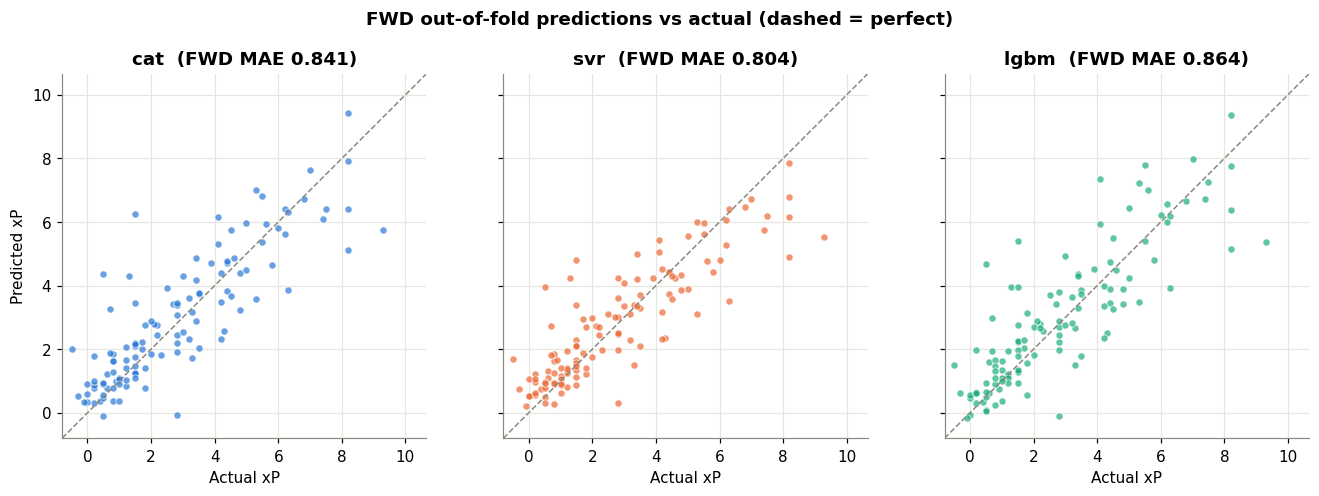

In [11]:
show = top3
fig, axes = plt.subplots(
    1, len(show), figsize=(4.2 * len(show), 4.2), sharex=True, sharey=True
)
lim = (min(oof.y.min(), oof.pred.min()) - 0.3, max(oof.y.max(), oof.pred.max()) + 0.3)
for ax, m in zip(axes, show):
    d = oof[oof.model == m]
    ax.plot(lim, lim, color="#8a8980", lw=1, ls="--")
    ax.scatter(
        d.y,
        d.pred,
        s=22,
        color=top_colors[m],
        alpha=0.7,
        edgecolor="white",
        linewidth=0.6,
    )
    ax.set_title(f"{m}  ({OOF_POS} MAE {oof_summary.loc[m, 'mae']:.3f})")
    ax.set_xlabel("Actual points")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
axes[0].set_ylabel("Predicted points")
plt.suptitle(
    f"{OOF_POS} out-of-fold predictions vs actual (dashed = perfect)",
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

In [12]:
# Where do the errors come from? MAE by actual-points band for the top models (OOF_POS).
bands = pd.cut(
    oof["y"], bins=[-np.inf, 2, 4, 6, np.inf], labels=["<2", "2–4", "4–6", "6+"]
)
(
    oof[oof.model.isin(top3 + [BASELINE])]
    .assign(band=bands)
    .pivot_table(
        index="band", columns="model", values="abs_err", aggfunc="mean", observed=True
    )
    .assign(n=bands.value_counts() / oof.model.nunique())[top3 + [BASELINE, "n"]]
)

model,cat,svr,lgbm,dummy,n
band,,,,,
<2,0.7375,0.6999,0.7086,2.0478,59.0
2–4,0.7911,0.6906,0.7757,0.3815,26.0
4–6,0.9300,0.8532,1.1786,1.8312,23.0
6+,1.2557,1.4141,1.1909,4.3855,13.0


## 7. Summary

The cell below prints the headline numbers. Validation sets are one gameweek per position (about 20 GK rows,
up to a few hundred MID rows), so rankings between close models can flip from fold to fold.
Prefer the average rank and the paired test over a single fold.


In [13]:
print(
    f"Best overall (mean MAE): {best}  MAE={leader.loc[best, 'mae_mean']:.4f}  R²={leader.loc[best, 'r2_mean']:.4f}"
)
print(
    f"Best by average rank:    {leader['avg_rank'].idxmin()}  (avg rank {leader['avg_rank'].min():.2f})"
)
print("Best per position (mean MAE):")
for p in POSITIONS:
    col = mae_pos[p].drop(BASELINE)
    print(
        f"  {p:>3}: {col.idxmin():<6} MAE={col.min():.4f}   runner-up {col.nsmallest(2).index[1]} ({col.nsmallest(2).iloc[1]:.4f})"
    )

Best overall (mean MAE): cat  MAE=0.7774  R²=0.6432
Best by average rank:    cat  (avg rank 2.88)
Best per position (mean MAE):
   GK: cat    MAE=0.8235   runner-up svr (0.8330)
  DEF: lgbm   MAE=0.7182   runner-up hgb (0.7229)
  MID: cat    MAE=0.7238   runner-up lgbm (0.7383)
  FWD: svr    MAE=0.7923   runner-up cat (0.8263)


## 8. Selection procedure and the gameweeks after each selection point

Same tables as `python src/compare.py`. `use_mae` is the MAE on the gameweeks each model would have been
used for (22 to 38), which played no part in choosing it. The `selected` row is the procedure itself:
the model with the lowest validation MAE at each selection point.


In [14]:
all_results, deploy = compare.load_results(), compare.load_deploy()
for p in POSITIONS:
    compare.print_table(all_results, deploy, p)



=== GK === selection points [21, 26, 31, 36], used for gameweeks 23-38 (14 gameweeks)
                    kind  valid_mae  valid_r2  use_mae  use_r2
label                                                         
ens_mean_base   ensemble      0.837     0.486    0.975   0.444
cat                 base      0.824     0.502    0.976   0.442
ens_top3        ensemble      0.847     0.477    0.977   0.442
xgb                 base      0.866     0.443    0.989   0.435
rf                  base      0.869     0.510    0.992   0.443
lgbm                base      0.843     0.466    1.006   0.419
selected       procedure          -         -    1.022   0.401
svr                 base      0.833     0.467    1.026   0.394
ridge               base      0.998     0.294    1.043   0.362
hgb                 base      0.844     0.502    1.044   0.373
dt                  base      0.937     0.426    1.054   0.355
dummy               base      1.241    -0.021    1.412  -0.034
selected: gw21 ens_top3, gw26 d

## 9. Performance per gameweek

MAE and R² of every gameweek from 21 to 38, one row per position, from `models/performance.csv`
(`src/performance.py`, the selected models) and `models/deploy_results.csv` (`src/deploy.py`, every model).

* **Blue:** the selection procedure. Each window between dotted lines uses the model named above it, which was
  picked at the selection point on the left of the window. Gameweek 21 is hollow because its predictions were
  used to pick that model.
* **Orange:** `ens_mean_base`, the same model in every gameweek, for reference.
* **Dashed:** the dummy baseline (MAE only; its R² is about 0, drawn as the zero line).
* **Grey lines:** every other fixed model.
* **Shaded:** gameweeks with no target in the source data, so nothing is scored there.


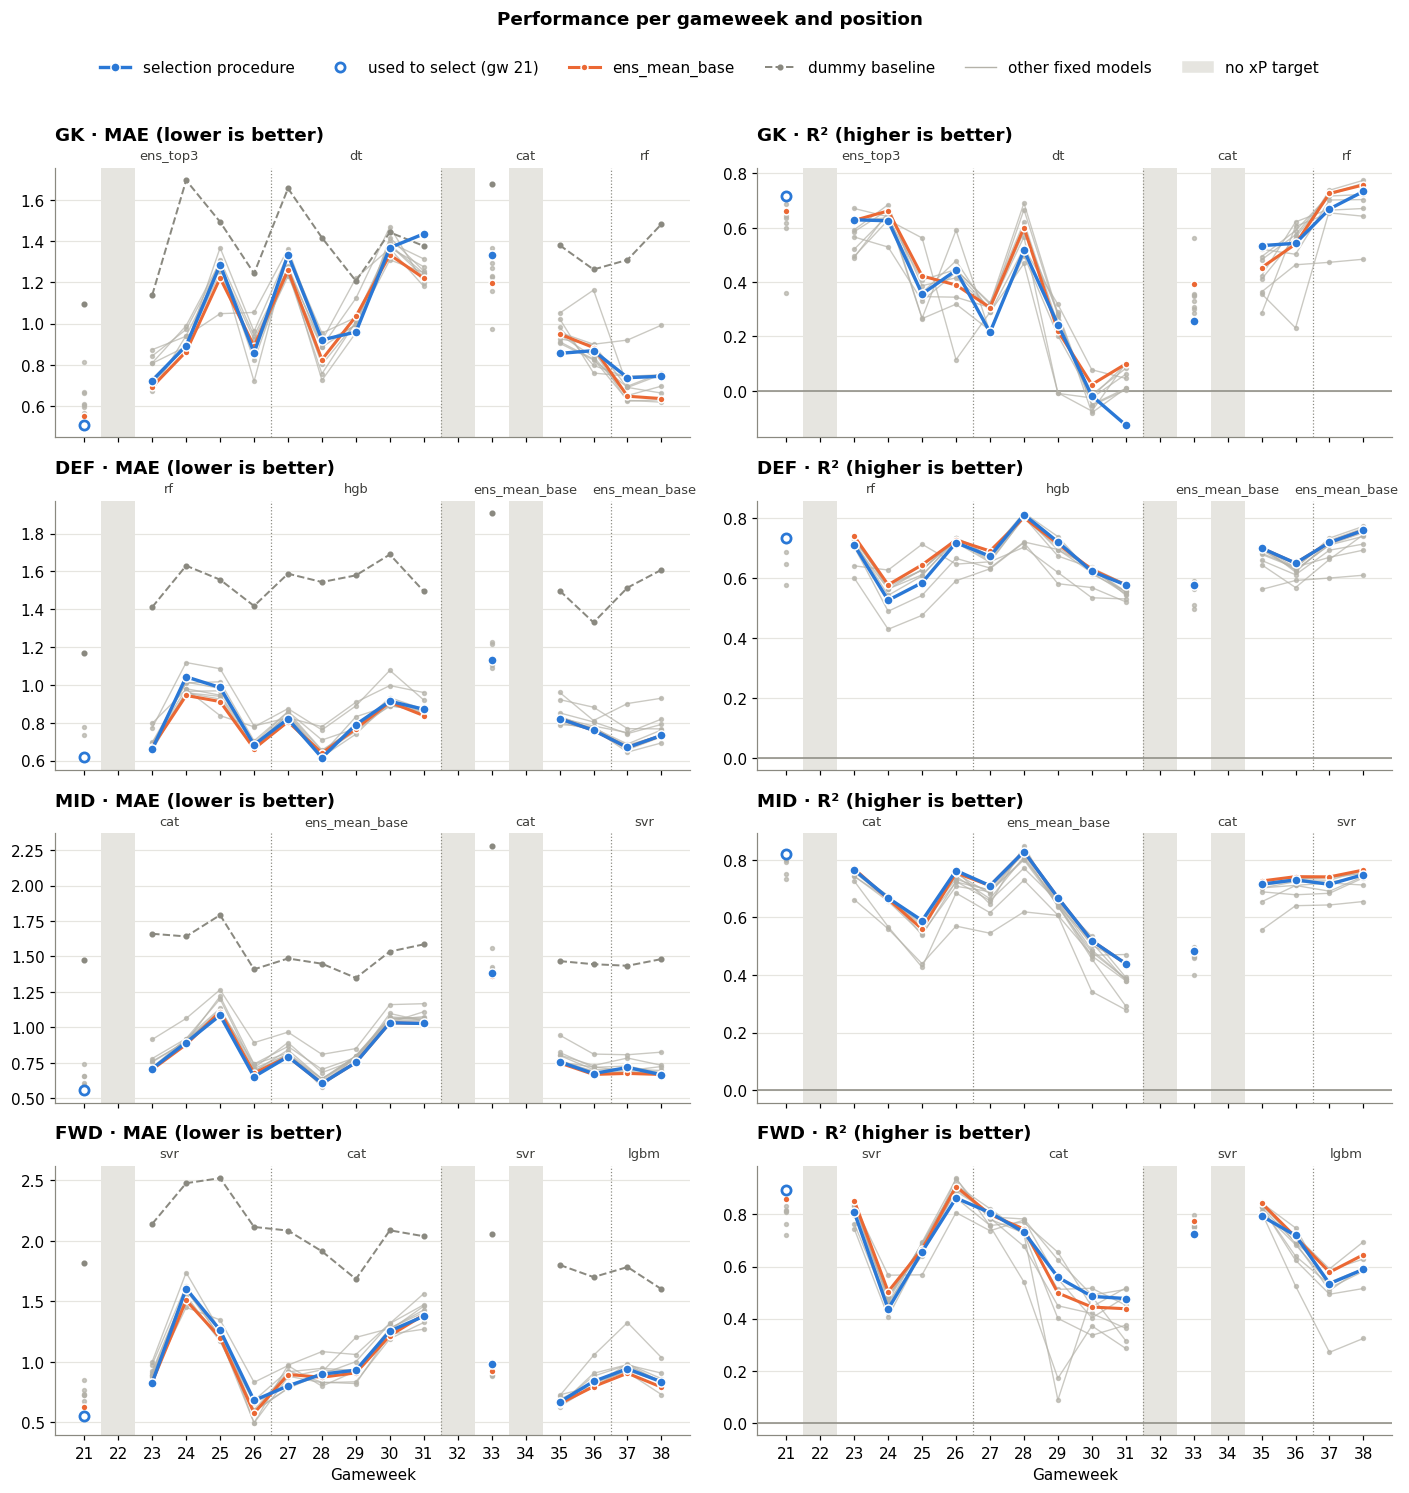

In [ ]:
perf = pd.read_csv(MODELS_DIR / "performance.csv")  # selected model per gameweek
deploy = pd.read_csv(
    MODELS_DIR / "deploy_results.csv"
)  # every model after each selection point

# Fixed models also need gameweek 21: their validation score at the first selection point
first = min(config.VALID_FOLDS)
at_first = all_results[all_results.fold == first].rename(columns={"label": "model"})
fixed = pd.concat(
    [
        deploy[["pos", "model", "gw", "mae", "r2"]],
        at_first.assign(gw=first)[["pos", "model", "gw", "mae", "r2"]],
    ]
)
GWS = list(range(first, perf["round"].max() + 1))
REFERENCE, INK, GRID_INK = "ens_mean_base", "#3d3d3a", "#8a8980"

fig, axes = plt.subplots(
    len(POSITIONS), 2, figsize=(13, 3.3 * len(POSITIONS)), sharex=True
)
for row, pos in zip(axes, POSITIONS):
    sel = perf[perf.pos == pos].set_index("round").reindex(GWS)
    fx = (
        fixed[fixed.pos == pos]
        .pivot_table(index="gw", columns="model", values=["mae", "r2"])
        .reindex(GWS)
    )
    for ax, metric, name in zip(
        row, ["mae", "r2"], ["MAE (lower is better)", "R² (higher is better)"]
    ):
        for g in config.MISSING_TARGET_GWS:
            ax.axvspan(g - 0.5, g + 0.5, color="#e6e5e0", lw=0, zorder=0)
        for s in config.VALID_FOLDS[1:]:
            ax.axvline(s + 0.5, color=GRID_INK, lw=0.8, ls=":", zorder=1)
        for m in fx[metric].columns:
            if m not in (REFERENCE, "dummy"):
                ax.plot(
                    GWS,
                    fx[metric][m],
                    color=MUTED,
                    lw=0.9,
                    alpha=0.7,
                    marker="o",
                    ms=2.5,
                    zorder=2,
                )
        if metric == "mae":
            ax.plot(
                GWS,
                fx[metric]["dummy"],
                color=GRID_INK,
                lw=1.3,
                ls="--",
                marker="o",
                ms=3,
                zorder=3,
            )
        else:
            ax.axhline(0, color=GRID_INK, lw=1, zorder=1)
        ax.plot(
            GWS,
            fx[metric][REFERENCE],
            color=ACCENT_2,
            lw=2,
            marker="o",
            ms=4.5,
            mec="white",
            mew=1,
            zorder=4,
        )
        scored = sel[metric].where(~sel.in_selection.fillna(False).astype(bool))
        ax.plot(
            GWS,
            scored,
            color=ACCENT,
            lw=2.2,
            marker="o",
            ms=6,
            mec="white",
            mew=1,
            zorder=5,
        )
        ax.plot(
            GWS,
            sel[metric].where(sel.in_selection.fillna(False).astype(bool)),
            ls="none",
            marker="o",
            ms=6,
            mfc="white",
            mec=ACCENT,
            mew=1.8,
            zorder=5,
        )
        ax.set_title(f"{pos} · {name}", loc="left", pad=18)
        ax.grid(axis="x", visible=False)
        # Model used in each window, above the plot
        for s in config.VALID_FOLDS:
            window = sel[sel.selected_at == s]
            x = (window.index.min() + window.index.max()) / 2
            ax.text(
                x,
                1.02,
                window.model.iloc[0],
                transform=ax.get_xaxis_transform(),
                ha="center",
                va="bottom",
                fontsize=8.5,
                color=INK,
            )
for ax in axes[-1]:
    ax.set_xticks(GWS)
    ax.set_xlabel("Gameweek")

handles = [
    plt.Line2D(
        [],
        [],
        color=ACCENT,
        lw=2.2,
        marker="o",
        ms=6,
        mec="white",
        label="selection procedure",
    ),
    plt.Line2D(
        [],
        [],
        ls="none",
        marker="o",
        ms=6,
        mfc="white",
        mec=ACCENT,
        mew=1.8,
        label="used to select (gw 21)",
    ),
    plt.Line2D(
        [], [], color=ACCENT_2, lw=2, marker="o", ms=4.5, mec="white", label=REFERENCE
    ),
    plt.Line2D(
        [],
        [],
        color=GRID_INK,
        lw=1.3,
        ls="--",
        marker="o",
        ms=3,
        label="dummy baseline",
    ),
    plt.Line2D([], [], color=MUTED, lw=0.9, label="other fixed models"),
    plt.matplotlib.patches.Patch(color="#e6e5e0", label="no target"),
]
fig.legend(
    handles=handles,
    loc="upper center",
    ncol=6,
    frameon=False,
    bbox_to_anchor=(0.5, 1.0),
)
fig.suptitle("Performance per gameweek and position", fontweight="bold", y=1.025)
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()


In [16]:
# The same numbers for the selection procedure, as a table ('-' = no target, gw 21 = used to select)
(
    perf.pivot_table(index="round", columns="pos", values=["mae", "r2"])
    .reindex(columns=POSITIONS, level=1)
    .reindex(GWS)
    .style.format(precision=3, na_rep="-")
    .background_gradient(subset=["mae"], cmap="Blues", axis=None)
)
